# PCA on Leaf Measurements

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 2 SIEC · 2024–2025  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Explore and visualize principal components of numeric leaf descriptors.

**Approach:** Standardization and principal component analysis.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


---

<div class="alert alert-success">

<center><b>University of Ghardaia</b></center>
    
<center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 2 SIEC - 2024/2025</i>
</center></div>

------

<br><br>

<center>
<span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>TP 1 exo 2 </span>
    </span>
    </center>
<br>


### 2. Load and Standardize the Data

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import scale

# Load the dataset
leaf = np.loadtxt('leaf.csv', delimiter=',')

# Print the first two rows to understand the structure
print("First two rows of the dataset:")
print(leaf[:2, :])

# Extract features (from column index 2 onwards) and standardize the data
leaf_features = leaf[:, 2:]
leaf_scaled = scale(leaf_features)


First two rows of the dataset:
[[1.0000e+00 1.0000e+00 7.2694e-01 1.4742e+00 3.2396e-01 9.8535e-01
  1.0000e+00 8.3592e-01 4.6566e-03 3.9465e-03 4.7790e-02 1.2795e-01
  1.6108e-02 5.2323e-03 2.7477e-04 1.1756e+00]
 [1.0000e+00 2.0000e+00 7.4173e-01 1.5257e+00 3.6116e-01 9.8152e-01
  9.9825e-01 7.9867e-01 5.2423e-03 5.0016e-03 2.4160e-02 9.0476e-02
  8.1195e-03 2.7080e-03 7.4846e-05 6.9659e-01]]


### 3. Apply PCA and Visualize Explained Variance



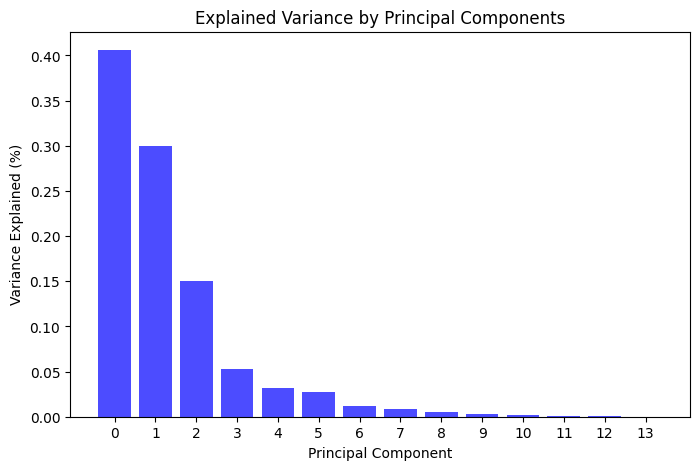

In [3]:
# Perform PCA
pca = PCA()
pca.fit(leaf_scaled)

# Explained variance ratio
explained_variance_ratios = pca.explained_variance_ratio_

# Visualize the explained variance
plt.figure(figsize=(8, 5))
plt.bar(range(len(explained_variance_ratios)), explained_variance_ratios, alpha=0.7, color='blue')
plt.xticks(range(len(explained_variance_ratios)))
plt.xlabel("Principal Component")
plt.ylabel("Variance Explained (%)")
plt.title("Explained Variance by Principal Components")
plt.show()


### 4. Project the Data onto the First 3 Principal Components


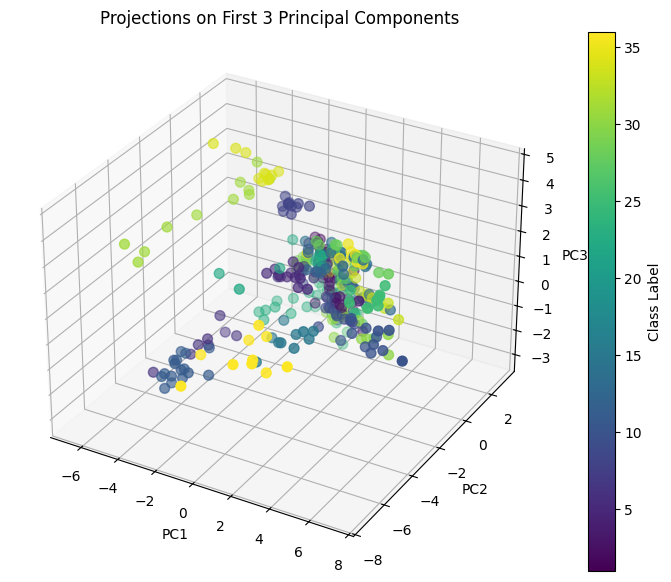

In [4]:
# Transform the data to the first 3 principal components
leaf_pca = pca.transform(leaf_scaled)

# Extract the class labels from the first column
class_labels = leaf[:, 0]

# Visualize the projections in 3D space
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Use class labels for color coding
scatter = ax.scatter(leaf_pca[:, 0], leaf_pca[:, 1], leaf_pca[:, 2], c=class_labels, cmap='viridis', s=50)
ax.set_title("Projections on First 3 Principal Components")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")

# Add a colorbar to indicate class labels
plt.colorbar(scatter, ax=ax, label="Class Label")
plt.show()
